Total records in dataset: 32950
Success probability (p): 0.11265553869499241
Mean (Expected successes): 5.632776934749621
Variance: 4.998213414816674
Standard Deviation: 2.235668449215284


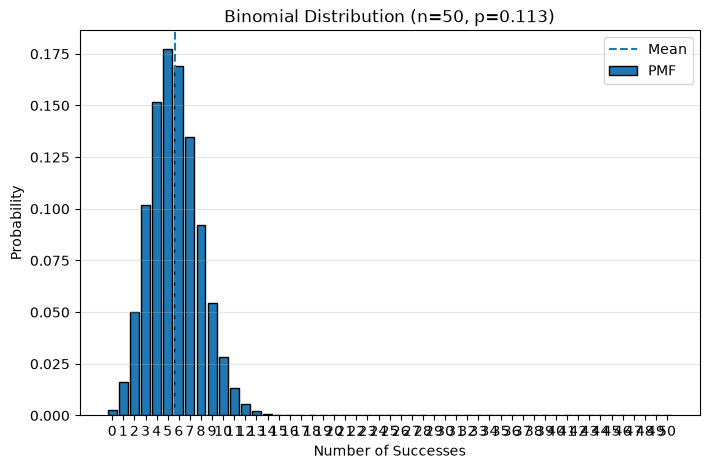

P(X >= 5): 0.6774990786971772
P(X = 8): 0.09199637646160543


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# 1. Load Kaggle dataset
df = pd.read_csv("new_train.csv")

# 2. Calculate probability of success from dataset
# y = yes means customer subscribed to the term deposit
p = (df["y"] == "yes").mean()

# Number of trials
n = 50

print("Total records in dataset:", len(df))
print("Success probability (p):", p)

# 3. Generate possible number of successes and probabilities
x = np.arange(0, n + 1)

pmf = binom.pmf(x, n, p)
cdf = binom.cdf(x, n, p)

# 4. Compute mean, variance and standard deviation
mean, var = binom.stats(n, p, moments="mv")
std_dev = np.sqrt(var)

print("Mean (Expected successes):", mean)
print("Variance:", var)
print("Standard Deviation:", std_dev)

# 5. Plot Binomial Distribution
plt.figure(figsize=(8, 5))

plt.bar(
    x,
    pmf,
    edgecolor="black",
    label="PMF"
)

plt.axvline(
    mean,
    linestyle="--",
    label="Mean"
)

plt.title(f"Binomial Distribution (n={n}, p={p:.3f})")
plt.xlabel("Number of Successes")
plt.ylabel("Probability")
plt.xticks(x)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

# 6. Probability of at least 5 successes
p_at_least_5 = 1 - binom.cdf(4, n, p)

print("P(X >= 5):", p_at_least_5)

# 7. Probability of exactly 8 successes
p_exactly_8 = binom.pmf(8, n, p)

print("P(X = 8):", p_exactly_8)